Dataset:
  Age Group Income  Buy
0     Young   High   No
1     Young    Low   No
2    Middle   High  Yes
3    Middle    Low  Yes
4       Old   High  Yes
5       Old   High  Yes
6     Young   High   No
7    Middle   High  Yes

--------------------------------
BASELINE ENTROPY
--------------------------------
Entropy H(S) = 0.9544

--------------------------------
BASELINE GINI IMPURITY
--------------------------------
Gini(S) = 0.4688

--------------------------------
INFORMATION GAIN
--------------------------------
IG(S, Age Group) = 0.9544
IG(S, Income) = 0.0157

--------------------------------
ROOT NODE
--------------------------------
Root Node = Age Group

--------------------------------
DECISION TREE
--------------------------------
Training Accuracy = 1.0


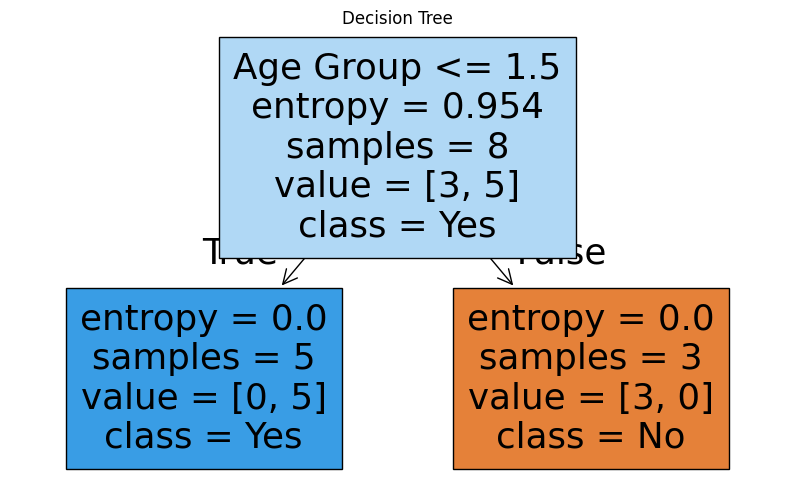

Depth = 1 Accuracy = 1.0
Depth = 2 Accuracy = 1.0
Depth = 3 Accuracy = 1.0
Depth = 4 Accuracy = 1.0
Depth = 5 Accuracy = 1.0


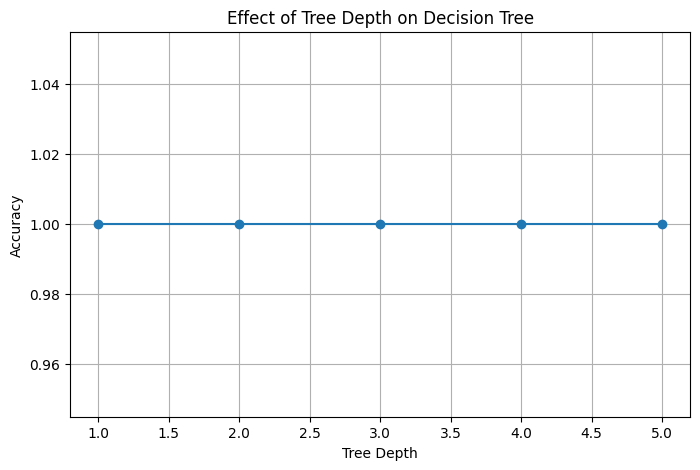

ccp_alpha = 0.0 Accuracy = 1.0
ccp_alpha = 0.9544 Accuracy = 0.625

--------------------------------
BEST CCP_ALPHA
--------------------------------
Best ccp_alpha = 0.0
Accuracy = 1.0


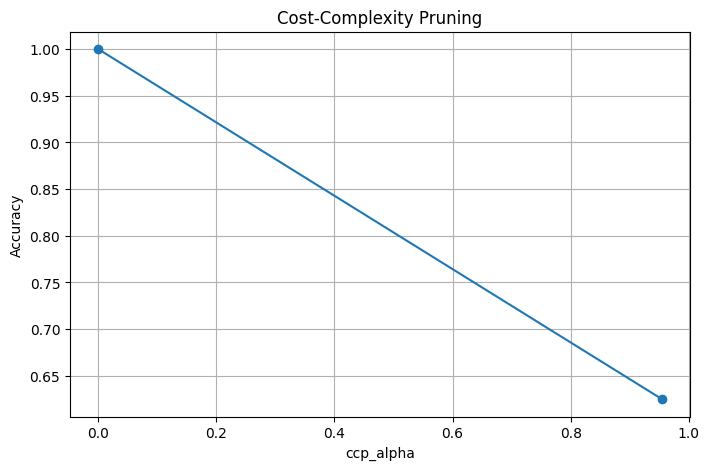

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from math import log2

from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Create dataset
df = pd.DataFrame({
    "Age Group": [
        "Young", "Young", "Middle", "Middle",
        "Old", "Old", "Young", "Middle"
    ],

    "Income": [
        "High", "Low", "High", "Low",
        "High", "High", "High", "High"
    ],

    "Buy": [
        "No", "No", "Yes", "Yes",
        "Yes", "Yes", "No", "Yes"
    ]
})

print("Dataset:")
print(df)


def entropy(target):
    counts = np.unique(
        target,
        return_counts=True
    )[1]

    probabilities = counts / counts.sum()

    return -sum(
        p * log2(p)
        for p in probabilities
    )


def gini_impurity(target):
    counts = np.unique(
        target,
        return_counts=True
    )[1]

    probabilities = counts / counts.sum()

    return 1 - sum(probabilities**2)


def information_gain(data, feature, target):

    total = entropy(data[target])

    weighted = sum(
        (len(group) / len(data)) * entropy(group[target])
        for _, group in data.groupby(feature)
    )

    return total - weighted


# Entropy, Gini and Information Gain
H_S = entropy(df["Buy"])
G_S = gini_impurity(df["Buy"])

IG_age = information_gain(
    df, "Age Group", "Buy"
)

IG_income = information_gain(
    df, "Income", "Buy"
)

print("\n--------------------------------")
print("BASELINE ENTROPY")
print("--------------------------------")

print("Entropy H(S) =", round(H_S, 4))

print("\n--------------------------------")
print("BASELINE GINI IMPURITY")
print("--------------------------------")

print("Gini(S) =", round(G_S, 4))

print("\n--------------------------------")
print("INFORMATION GAIN")
print("--------------------------------")

print("IG(S, Age Group) =", round(IG_age, 4))
print("IG(S, Income) =", round(IG_income, 4))

root = (
    "Age Group"
    if IG_age > IG_income
    else "Income"
)

print("\n--------------------------------")
print("ROOT NODE")
print("--------------------------------")

print("Root Node =", root)

# Encode categories
encoders = {
    col: LabelEncoder()
    for col in df.columns
}

encoded = df.copy()

for col, encoder in encoders.items():
    encoded[col] = encoder.fit_transform(df[col])

X = encoded[["Age Group", "Income"]]
y = encoded["Buy"]

# Train decision tree
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X, y)

y_pred = model.predict(X)

accuracy = accuracy_score(y, y_pred)

print("\n--------------------------------")
print("DECISION TREE")
print("--------------------------------")

print("Training Accuracy =", accuracy)

# Plot decision tree
plt.figure(figsize=(10, 6))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoders["Buy"].classes_,
    filled=True
)

plt.title("Decision Tree")
plt.show()

# Compare accuracy across tree depths
depths = range(1, 6)
train_accuracies = []

for depth in depths:

    tree = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=depth,
        random_state=42
    ).fit(X, y)

    score = accuracy_score(
        y,
        tree.predict(X)
    )

    train_accuracies.append(score)

    print(
        "Depth =", depth,
        "Accuracy =", round(score, 4)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    depths,
    train_accuracies,
    marker="o"
)

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Decision Tree")
plt.grid()
plt.show()

# Cost-complexity pruning
path = model.cost_complexity_pruning_path(X, y)

ccp_alphas = path.ccp_alphas

pruned_accuracies = []

for alpha in ccp_alphas:

    tree = DecisionTreeClassifier(
        criterion="entropy",
        ccp_alpha=alpha,
        random_state=42
    ).fit(X, y)

    score = accuracy_score(
        y,
        tree.predict(X)
    )

    pruned_accuracies.append(score)

    print(
        "ccp_alpha =",
        round(alpha, 4),
        "Accuracy =",
        round(score, 4)
    )

best_index = np.argmax(pruned_accuracies)

best_alpha = ccp_alphas[best_index]
best_accuracy = pruned_accuracies[best_index]

print("\n--------------------------------")
print("BEST CCP_ALPHA")
print("--------------------------------")

print("Best ccp_alpha =", round(best_alpha, 4))
print("Accuracy =", round(best_accuracy, 4))

plt.figure(figsize=(8, 5))

plt.plot(
    ccp_alphas,
    pruned_accuracies,
    marker="o"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Accuracy")
plt.title("Cost-Complexity Pruning")
plt.grid()
plt.show()